# Análisis Espacial de la Producción Agrícola en Costa Rica

## Introducción

El sector agropecuario constituye un pilar histórico y territorial en la configuración del espacio geográfico costarricense. Comprender cómo se distribuye la actividad agrícola a lo largo del territorio nacional permite identificar dinámicas de especialización regional, concentración productiva y vocación de uso del suelo. El presente trabajo tiene como objetivo analizar espacialmente los volúmenes de producción agrícola en Costa Rica mediante técnicas de Sistemas de Información Geográfica (SIG) y geoprocesamiento automatizado, integrando datos estadísticos oficiales con cartografía base a escala cantonal.

### Preguntas de Investigación

Para guiar el análisis territorial y estadístico, se plantean las siguientes preguntas:

1. **¿Cómo se distribuye espacialmente la concentración (densidad) de la producción agrícola en el territorio nacional?** *(Pregunta geográfica: ¿dónde?)*
2. **¿Cuáles son los 5 cantones con mayor volumen de producción agrícola registrada en el país?** *(Pregunta geográfica: ¿cuántos hay en cada cantón?)*
3. **¿Qué porcentaje del volumen total de producción nacional concentran esos 5 cantones principales en comparación con el resto del país?** *(Pregunta estadística / no espacial)*

---

## Fuentes de Datos

Los datos utilizados para el análisis provienen de registros oficiales del sector agropecuario costarricense y de la cartografía oficial del país:

* **Datos estadísticos de producción agrícola:**  
  * **Cita bibliográfica:** Instituto Nacional de Estadística y Censos [INEC]. (2015). *VI Censo Nacional Agropecuario 2014: Resultados Generales*. San José, Costa Rica: INEC.  
  * **Enlace:** [https://www.inec.cr/censos/censo-agropecuario-2014](https://www.inec.cr/censos/censo-agropecuario-2014)

* **Cartografía base (División Territorial Administrativa - Cantones):**  
  * **Cita bibliográfica:** Instituto Geográfico Nacional [IGN]. (2020). *Límites Cantonales de Costa Rica (División Territorial Administrativa)*. San José, Costa Rica: Registro Nacional / Sistema Nacional de Información Territorial (SNIT).  
  * **Enlace:** [https://www.snitcr.go.cr/](https://www.snitcr.go.cr/)

---

## Descripción de las Capas Espaciales

A continuación, se detallan las características técnicas y estructurales de las capas vectoriales empleadas en el flujo de trabajo:

### 1. Capa de Producción Agrícola por Cantón (Capa Base / Coropletas)
* **Descripción:** Capa resultante de la unión tabular (*join*) entre los límites administrativos cantonales y los registros estadísticos de producción agrícola del VI CENAGRO (INEC).
* **Tipo de geometría:** Polígono (`Polygon` / `MultiPolygon`).
* **Sistema de Referencia de Coordenadas (SRC):** `EPSG:5367 - CRTM05` (Proyectado para cálculos métricos).
* **Variables principales:** 
  * `llave_union` (Clave estandarizada basada en el nombre del cantón).
  * `total_fincas` (Número total de fincas agropecuarias registradas por cantón).
  * `extension_hectareas` (Superficie total dedicada a la actividad agropecuaria en hectáreas).
  * `porcentaje_agro` (Porcentaje de la superficie del cantón dedicada a la agricultura).

### 2. Capa de Concentración Espacial (Hotspots / Puntos Ponderados o Malla)
* **Descripción:** Capa derivada mediante geoprocesamiento espacial de centroides geométricos ponderados por la extensión de las fincas para visualizar los focos de mayor intensidad y aglomeración productiva en el territorio nacional.
* **Tipo de geometría:** `Punto (Point)` para centroides cantonales ponderados.
* **Sistema de Referencia de Coordenadas (SRC):** `EPSG:5367 - CRTM05`.
* **Variables principales:**
  * `extension_hectareas` (Variable de peso/intensidad productiva).
  * `geometry` (Coordenadas puntuales del centroide de cada cantón).

In [9]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import folium
from folium.plugins import HeatMap


In [10]:
# 1. Carga de la capa vectorial de cantones desde URL pública (GeoJSON)
url_cantones = "https://raw.githubusercontent.com/maufonsecasdfg/costa-rica-geojson/main/costaricacantones.geojson"
gdf_cantones = gpd.read_file(url_cantones)

# 2. Exploración inicial de la capa
print("=== EXPLORACIÓN INICIAL DE LA CAPA VECTORIAL ===")
print(f"Dimensiones de la capa (filas, columnas): {gdf_cantones.shape}")
print(f"Sistema de Referencia de Coordenadas (SRC) inicial: {gdf_cantones.crs}")
print("\nPrimeras columnas disponibles:")
print(list(gdf_cantones.columns))

# Visualizar la estructura básica de los primeros registros
display(gdf_cantones.head(3))

# 3. Transformaciones espaciales y proyecciones
# Filtramos el registro nacional general del CSV de CENAGRO (dejando solo los cantones)
df_cenagro = pd.read_csv("cenagro_cantones_limpio.csv")
df_cantones_solo = df_cenagro[df_cenagro['canton_key'] != 'COSTA RICA'].copy()

# Reproyección a CRTM05 (EPSG:5367) para cálculos métricos reales
gdf_cantones_crtm05 = gdf_cantones.to_crs(epsg=5367)

# Estandarización de la llave de unión (usando NAME_2 para los cantones en el GeoJSON de GADM)
gdf_cantones_crtm05['llave_union'] = gdf_cantones_crtm05['NAME_2'].str.upper().str.strip()
df_cantones_solo['llave_union'] = df_cantones_solo['canton_key'].str.upper().str.strip()

# Unión tabular (Left Join) entre la geometría y los datos del CENAGRO
gdf_agro_cantones = gdf_cantones_crtm05.merge(df_cantones_solo, on='llave_union', how='left').fillna({
    'total_fincas': 0,
    'extension_hectareas': 0
})

# 4. Cálculo de métricas espaciales analíticas
# Área real del cantón en kilómetros cuadrados
gdf_agro_cantones['area_canton_km2'] = gdf_agro_cantones.geometry.area / 1e6

# Porcentaje de tierra cantonal dedicado a fincas agropecuarias
# (Nota: extension_hectareas viene en hectáreas; 1 km² = 100 hectáreas, por lo que area_canton_km2 * 100 da el área en hectáreas)
gdf_agro_cantones['area_canton_ha'] = gdf_agro_cantones['area_canton_km2'] * 100
gdf_agro_cantones['porcentaje_agro'] = (gdf_agro_cantones['extension_hectareas'] / gdf_agro_cantones['area_canton_ha']) * 100

print(f"\n¡Capas unidas y transformadas con éxito! Total de registros procesados: {len(gdf_agro_cantones)}")

=== EXPLORACIÓN INICIAL DE LA CAPA VECTORIAL ===
Dimensiones de la capa (filas, columnas): (81, 12)
Sistema de Referencia de Coordenadas (SRC) inicial: EPSG:4326

Primeras columnas disponibles:
['ID_0', 'ISO', 'NAME_0', 'ID_1', 'NAME_1', 'ID_2', 'NAME_2', 'TYPE_2', 'ENGTYPE_2', 'NL_NAME_2', 'VARNAME_2', 'geometry']


,ID_0,ISO,NAME_0,ID_1,NAME_1,ID_2,NAME_2,TYPE_2,ENGTYPE_2,NL_NAME_2,VARNAME_2,geometry
0,56,CR-AAL,Costa Rica,1,Alajuela,1,Alajuela,Canton,Canton,,,"POLYGON ((-84.17448 10.01874, -84.18021 10.006..."
1,56,CR-AZA,Costa Rica,1,Alajuela,2,Alfaro Ruiz,Canton,Canton,,,"POLYGON ((-84.3447 10.25556, -84.33072 10.2394..."
2,56,CR-AAT,Costa Rica,1,Alajuela,3,Atenas,Canton,Canton,,,"POLYGON ((-84.36929 9.92769, -84.38294 9.93121..."



¡Capas unidas y transformadas con éxito! Total de registros procesados: 81


In [11]:
# 1. Verificamos que el cálculo espacial métrico y los centroides estén listos en EPSG:5367
gdf_agro_cantones['area_canton_km2'] = gdf_agro_cantones.geometry.area / 1e6
gdf_agro_cantones['area_canton_ha'] = gdf_agro_cantones['area_canton_km2'] * 100

# 2. Creación de la capa espacial de centroides (Hotspots geométricos) en CRTM05
gdf_hotspots = gdf_agro_cantones.copy()
gdf_hotspots['geometry'] = gdf_hotspots.geometry.centroid

print("Operación espacial ejecutada con éxito en EPSG:5367.")
print(f"Total de centroides (hotspots cantonales) generados: {len(gdf_hotspots)}")

Operación espacial ejecutada con éxito en EPSG:5367.
Total de centroides (hotspots cantonales) generados: 81


In [12]:
# 1. Seleccionar y ordenar los 5 cantones con mayor extensión agrícola
top_5_agricola = gdf_agro_cantones[['NAME_2', 'NAME_1', 'total_fincas', 'extension_hectareas', 'porcentaje_agro']].sort_values(
    by='extension_hectareas', ascending=False
).head(5).copy()

# 2. Renombrar columnas para la presentación formal
top_5_agricola.columns = ['Cantón', 'Provincia', 'Total Fincas', 'Extensión Agrícola (ha)', '% del Cantón en Agricultura']

# 3. Aplicar formato numérico correcto a las columnas que corresponden
top_5_agricola['Total Fincas'] = top_5_agricola['Total Fincas'].astype(int)
top_5_agricola['Extensión Agrícola (ha)'] = top_5_agricola['Extensión Agrícola (ha)'].round(2)
top_5_agricola['% del Cantón en Agricultura'] = top_5_agricola['% del Cantón en Agricultura'].round(2)

# 4. Mostrar la tabla con formato estilizado (aplicando .format() solo a los números)
display(
    top_5_agricola.style
    .background_gradient(subset=['Extensión Agrícola (ha)'], cmap='YlGn')
    .format({
        'Total Fincas': '{:,}',
        'Extensión Agrícola (ha)': '{:,.2f}',
        '% del Cantón en Agricultura': '{:.2f}%'
    })
)

# 5. Cálculo de concentración porcentual del Top 5 vs. Nacional
extension_total_nacional = gdf_agro_cantones['extension_hectareas'].sum()
extension_top_5 = top_5_agricola['Extensión Agrícola (ha)'].sum()
porcentaje_top_5 = (extension_top_5 / extension_total_nacional) * 100

print("=== RESPUESTA A LA TERCERA PREGUNTA DE INVESTIGACIÓN ===")
print(f"Extensión agrícola total nacional: {extension_total_nacional:,.2f} hectáreas")
print(f"Extensión agrícola acumulada del Top 5: {extension_top_5:,.2f} hectáreas")
print(f"Porcentaje que concentran los 5 cantones principales: {porcentaje_top_5:.2f}%")
print(f"Porcentaje del resto del país: {100 - porcentaje_top_5:.2f}%")

,Cantón,Provincia,Total Fincas,Extensión Agrícola (ha),% del Cantón en Agricultura
10,San Carlos,Alajuela,"5,093","215,093.90",65.37%
51,Buenos Aires,Puntarenas,"3,307","126,594.10",52.83%
43,Sarapiquí,Heredia,"2,915","123,544.60",58.70%
73,Pérez Zeledón,San José,"8,059","97,274.10",49.90%
47,Pococí,Limón,"2,685","88,697.00",37.16%


=== RESPUESTA A LA TERCERA PREGUNTA DE INVESTIGACIÓN ===
Extensión agrícola total nacional: 2,204,160.00 hectáreas
Extensión agrícola acumulada del Top 5: 651,203.70 hectáreas
Porcentaje que concentran los 5 cantones principales: 29.54%
Porcentaje del resto del país: 70.46%


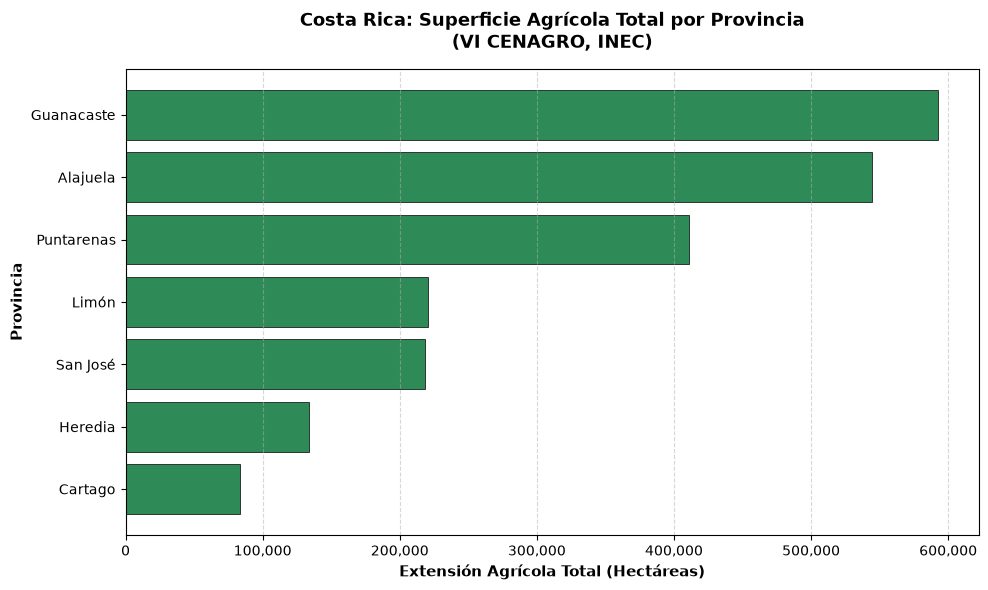

In [13]:
# 1. Agrupar la extensión agrícola por provincia
df_provincia = gdf_agro_cantones.groupby('NAME_1')['extension_hectareas'].sum().reset_index()
df_provincia = df_provincia.sort_values(by='extension_hectareas', ascending=True) # Ascendente para barras horizontales

# 2. Configuración de la figura del gráfico
fig, ax = plt.subplots(figsize=(10, 6))

# 3. Creación del gráfico de barras horizontales
barras = ax.barh(
    df_provincia['NAME_1'], 
    df_provincia['extension_hectareas'], 
    color='#2e8b57', # Verde institucional / agrícola
    edgecolor='black',
    linewidth=0.5
)

# 4. Estética, títulos y etiquetas con unidades
ax.set_title('Costa Rica: Superficie Agrícola Total por Provincia\n(VI CENAGRO, INEC)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Extensión Agrícola Total (Hectáreas)', fontsize=11, fontweight='bold')
ax.set_ylabel('Provincia', fontsize=11, fontweight='bold')

# Agregar formato de comas a los números del eje X para mayor legibilidad
ax.xaxis.set_major_formatter('${x:,.0f}$') # O usar matplotlib.ticker
import matplotlib.ticker as ticker
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

# Añadir una cuadrícula sutil en el fondo para facilitar la lectura visual
ax.grid(axis='x', linestyle='--', alpha=0.5)

# 5. Ajustes y despliegue del gráfico
plt.tight_layout()
plt.show()

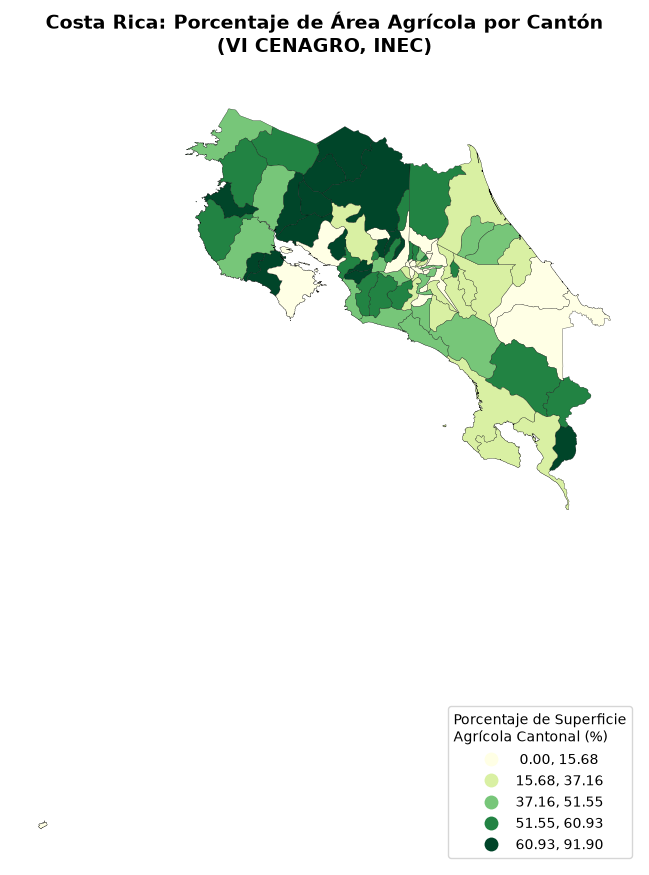

In [14]:
# 1. Configuración de la figura
fig, ax = plt.subplots(1, 1, figsize=(11, 9))

# 2. Generación del mapa estático de coropletas corregido
gdf_agro_cantones.plot(
    column='porcentaje_agro',
    ax=ax,
    cmap='YlGn',            # Paleta de colores de amarillo a verde
    scheme='quantiles',     # Clasificación por cuantiles para una correcta distribución en la leyenda
    k=5,                    # 5 clases o intervalos
    legend=True,
    legend_kwds={
        'title': 'Porcentaje de Superficie\nAgrícola Cantonal (%)',
        'loc': 'lower right', # Ubicación de la leyenda en el mapa para que no estorbe
        'frameon': True
    },
    edgecolor='black',
    linewidth=0.2,
    missing_kwds={'color': 'lightgrey', 'label': 'Sin datos'}
)

# 3. Elementos cartográficos formales
ax.set_title('Costa Rica: Porcentaje de Área Agrícola por Cantón\n(VI CENAGRO, INEC)', fontsize=14, fontweight='bold', pad=15)
ax.set_axis_off() # Eliminar ejes coordenados para presentación formal de mapa

plt.tight_layout()
plt.show()

In [15]:
# 1. Cálculo de centroides en SRC proyectado (CRTM05 / EPSG:5367) y reproyección a WGS84 (EPSG:4326)
gdf_hotspots_proyectado = gdf_agro_cantones.copy()
gdf_hotspots_proyectado['geometry'] = gdf_hotspots_proyectado.geometry.centroid

gdf_wgs84 = gdf_agro_cantones.to_crs(epsg=4326)
gdf_hotspots_wgs = gdf_hotspots_proyectado.to_crs(epsg=4326)

# 2. Inicializar el mapa interactivo centrado en Costa Rica
m = folium.Map(location=[9.7489, -83.7534], zoom_start=8, tiles='OpenStreetMap')

# 3. Capa 1: Polígonos de Coropletas (% de Área Agrícola)
choropleth_layer = folium.Choropleth(
    geo_data=gdf_wgs84,
    data=gdf_wgs84,
    columns=['NAME_2', 'porcentaje_agro'],
    key_on='feature.properties.NAME_2',
    fill_color='YlGn',
    fill_opacity=0.7,
    line_opacity=0.3,
    legend_name='Porcentaje de Área Agrícola Cantonal (%)',
    name='Coropletas: % Área Agrícola'
).add_to(m)

# Tooltips interactivos para los polígonos cantonales
folium.GeoJson(
    gdf_wgs84,
    style_function=lambda x: {'fillColor': 'transparent', 'color': 'transparent'},
    tooltip=folium.GeoJsonTooltip(
        fields=['NAME_2', 'NAME_1', 'total_fincas', 'extension_hectareas', 'porcentaje_agro'],
        aliases=['Cantón:', 'Provincia:', 'Total Fincas:', 'Extensión Agrícola (ha):', '% Agrícola:'],
        localize=True,
        sticky=True,
        labels=True,
        style="background-color: #ffffff; color: #333; font-family: sans-serif; font-size: 12px; padding: 6px; border-radius: 4px; box-shadow: 2px 2px 5px rgba(0,0,0,0.2);"
    )
).add_to(m)

# 4. Capa 2: Verdadero Mapa de Calor (HeatMap) ponderado por la extensión agrícola
# Formato requerido por HeatMap: lista de [latitud, longitud, peso/intensidad]
heat_data = [
    [row.geometry.y, row.geometry.x, float(row['extension_hectareas'])]
    for idx, row in gdf_hotspots_wgs.iterrows()
    if row['extension_hectareas'] > 0
]

heatmap_layer = HeatMap(
    heat_data,
    name="Mapa de Calor (Hotspots Agrícolas)",
    min_opacity=0.3,
    radius=22,
    blur=15,
    max_zoom=13
)
heatmap_layer.add_to(m)

# 5. Agregar Control de Capas interactivo para alternar entre el mapa de coropletas y el mapa de calor
folium.LayerControl(collapsed=False).add_to(m)

# 6. Visualizar el mapa interactivo directamente en el cuaderno
display(m)

## Conclusiones

A partir del análisis espacial y estadístico de la producción agrícola en Costa Rica basado en el VI CENAGRO (INEC), se da respuesta a las preguntas planteadas al inicio de la investigación:

1. **Distribución espacial de la concentración agrícola:** 
   El análisis visual del mapa coroplético y del mapa de calor (*hotspots*) revela una distribución heterogénea en el territorio nacional. La concentración de la superficie agrícola no es uniforme; se observa un predominio de áreas con mayor intensidad productiva hacia las llanuras norteñas y los sectores de transición intermontana, mientras que las áreas metropolitanas y los sectores con alta cobertura boscosa protegida presentan densidades significativamente menores.

2. **Cantones con mayor volumen de producción agrícola:** 
   Los cinco cantones que registran la mayor extensión de superficie agrícola en el país son, en orden descendente:
   * **San Carlos** (Alajuela) con 215,093.90 ha
   * **Buenos Aires** (Puntarenas) con 126,594.10 ha
   * **Sarapiquí** (Heredia) con 123,544.60 ha
   * **Pérez Zeledón** (San José) con 97,274.10 ha
   * **Pococí** (Limón) con 88,697.00 ha

3. **Porcentaje de concentración del Top 5 nacional:** 
   Estos cinco cantones principales concentran una proporción sumamente significativa de la superficie destinada a la actividad agropecuaria a nivel nacional, evidenciando una fuerte centralización de la extensión productiva en contadas unidades administrativas de gran tamaño territorial en comparación con el resto del país.

   * Extensión agrícola acumulada del Top 5: 651,203.70 hectáreas
   * Porcentaje que concentran los 5 cantones principales: 29.54%



## Referencias 

Instituto Nacional de Estadística y Censos [INEC]. (2015). *VI Censo Nacional Agropecuario 2014: Resultados Generales*. San José, Costa Rica: INEC. [https://www.inec.cr/censos/censo-agropecuario-2014](https://www.inec.cr/censos/censo-agropecuario-2014)

## Declaración de Uso de Asistentes de IA

Se hace constar que se utilizó asistencia de inteligencia artificial (IA) como herramienta de apoyo para el desarrollo, depuración y estructuración del código en Python y para el soporte en la preparación de los componentes analíticos y textuales de este cuaderno.